# Tugas Take Home Sesi 05: Transfer Learning

Dataset: Oxford-IIIT Pet, 10 kelas (5 kucing dan 5 anjing). Model utama: ResNet-18.

Di notebook ini ada 5 percobaan: B1 (from scratch), B2 (feature extraction), B3 (fine-tuning), B4 (dengan dan tanpa augmentasi), dan B5 (model lain sebagai pembanding).

## 1. Import dan pengaturan

Semua pengaturan (seed, batch size, learning rate, dll) ditaruh di sini supaya mudah diubah.

In [ ]:
import os
import copy
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 4
WEIGHT_DECAY = 0.01
LR_SCRATCH = 1e-3
LR_HEAD = 1e-3
LR_BLOCK = 1e-4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

os.makedirs("results/figures", exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

device: cuda


## 2. Menyiapkan data

Dataset diunduh, lalu diambil 10 kelas saja. Data dibagi menjadi train 70%, validation 15%, dan test 15% dengan stratified split supaya proporsi kelasnya sama.

In [ ]:
cat_breeds = ["Abyssinian", "Bengal", "Birman", "Ragdoll", "Siamese"]
dog_breeds = ["Beagle", "Boxer", "Pug", "Samoyed", "Shiba Inu"]
class_names = cat_breeds + dog_breeds

train_val_set = datasets.OxfordIIITPet("data", split="trainval", target_types="category", download=True)
test_set = datasets.OxfordIIITPet("data", split="test", target_types="category", download=True)

all_paths = list(train_val_set._images) + list(test_set._images)
all_labels = list(train_val_set._labels) + list(test_set._labels)
original_names = train_val_set.classes

paths = []
labels = []
for p, l in zip(all_paths, all_labels):
    name = original_names[l]
    if name in class_names:
        paths.append(p)
        labels.append(class_names.index(name))
labels = np.array(labels)
print("jumlah gambar:", len(paths))

idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)
print("train:", len(train_idx), "| val:", len(val_idx), "| test:", len(test_idx))

split_table = pd.DataFrame({
    "kelas": class_names,
    "train": np.bincount(labels[train_idx], minlength=10),
    "val": np.bincount(labels[val_idx], minlength=10),
    "test": np.bincount(labels[test_idx], minlength=10),
})
split_table

100%|██████████| 792M/792M [00:37<00:00, 21.0MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.51MB/s]


jumlah gambar: 1996
train: 1397 | val: 299 | test: 300


,kelas,train,val,test
0,Abyssinian,139,29,30
1,Bengal,140,30,30
2,Birman,140,30,30
3,Ragdoll,140,30,30
4,Siamese,139,30,30
5,Beagle,140,30,30
6,Boxer,139,30,30
7,Pug,140,30,30
8,Samoyed,140,30,30
9,Shiba Inu,140,30,30


## 3. Transformasi dan DataLoader

Augmentasi hanya dipakai untuk data train. Data validation dan test hanya di-resize, di-crop, dan dinormalisasi memakai mean dan std ImageNet.

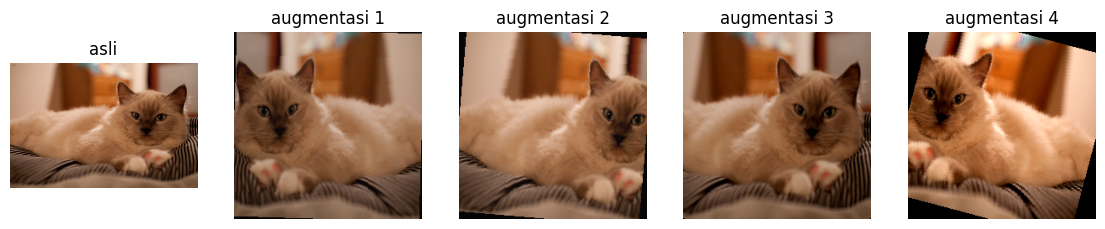

In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


class PetDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])


train_paths = [paths[i] for i in train_idx]
val_paths = [paths[i] for i in val_idx]
test_paths = [paths[i] for i in test_idx]

train_data_aug = PetDataset(train_paths, labels[train_idx], train_transform)
train_data_plain = PetDataset(train_paths, labels[train_idx], test_transform)
val_data = PetDataset(val_paths, labels[val_idx], test_transform)
test_data = PetDataset(test_paths, labels[test_idx], test_transform)

train_loader_aug = DataLoader(train_data_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
train_loader_plain = DataLoader(train_data_plain, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
train_eval_loader = DataLoader(train_data_plain, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


def denorm(x):
    x = x.clone()
    for c in range(3):
        x[c] = x[c] * std[c] + mean[c]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


sample = Image.open(train_paths[0]).convert("RGB")
plt.figure(figsize=(14, 3))
plt.subplot(1, 5, 1)
plt.imshow(sample)
plt.title("asli")
plt.axis("off")
for k in range(4):
    plt.subplot(1, 5, k + 2)
    plt.imshow(denorm(train_transform(sample)))
    plt.title("augmentasi " + str(k + 1))
    plt.axis("off")
plt.savefig("results/figures/augmentation_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Membuat model

Ada tiga cara melatih model:
- scratch: bobot acak, semua layer dilatih
- feature_extraction: bobot ImageNet, semua layer dibekukan kecuali layer klasifikasi yang baru
- finetune_last: layer terakhir (layer4 pada ResNet-18) dan layer klasifikasi dilatih, sisanya dibekukan. Learning rate layer4 dibuat lebih kecil daripada fc.

In [ ]:
def get_model(arch, mode):
    if mode == "scratch":
        weights = None
    else:
        weights = "IMAGENET1K_V1"

    if arch == "resnet18":
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(512, 10)
        last_block = model.layer4
        head = model.fc
    elif arch == "efficientnet_b0":
        model = models.efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(1280, 10)
        last_block = model.features[7:]
        head = model.classifier

    if mode == "scratch":
        groups = [{"params": list(model.parameters()), "lr": LR_SCRATCH}]
    elif mode == "feature_extraction":
        for p in model.parameters():
            p.requires_grad = False
        for p in head.parameters():
            p.requires_grad = True
        groups = [{"params": list(head.parameters()), "lr": LR_HEAD}]
    else:
        for p in model.parameters():
            p.requires_grad = False
        for p in last_block.parameters():
            p.requires_grad = True
        for p in head.parameters():
            p.requires_grad = True
        groups = [
            {"params": list(last_block.parameters()), "lr": LR_BLOCK},
            {"params": list(head.parameters()), "lr": LR_HEAD},
        ]

    return model.to(device), groups


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


for mode in ["scratch", "feature_extraction", "finetune_last"]:
    m, g = get_model("resnet18", mode)
    print(mode, "->", count_params(m))
del m, g

scratch -> (11181642, 11181642)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


feature_extraction -> (5130, 11181642)
finetune_last -> (8398858, 11181642)


## 5. Fungsi training dan evaluasi

Training memakai early stopping berdasarkan validation loss (patience 4). Setelah training selesai, bobot dari epoch dengan validation loss terkecil dipakai lagi untuk evaluasi akhir.

Layer BatchNorm yang dibekukan dikembalikan ke mode eval setiap epoch, karena `requires_grad = False` saja tidak menghentikan BatchNorm memperbarui statistiknya.

In [ ]:
results = {}


def evaluate(model, loader):
    model.eval()
    all_logits = []
    all_labels = []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            all_logits.append(out.cpu())
            all_labels.append(y)
    logits = torch.cat(all_logits)
    y = torch.cat(all_labels)
    loss = F.cross_entropy(logits, y).item()
    probs = logits.softmax(dim=1).numpy()
    preds = probs.argmax(axis=1)
    y = y.numpy()
    return {
        "loss": loss,
        "acc": accuracy_score(y, preds),
        "f1": f1_score(y, preds, average="macro"),
        "probs": probs,
        "preds": preds,
        "labels": y,
    }


def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
            m.eval()

    total_loss = 0
    correct = 0
    n = 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def save_logs():
    all_history = []
    all_summary = []
    for name in results:
        all_history = all_history + results[name]["history"]
        all_summary.append(results[name]["summary"])

    pd.DataFrame(all_history).to_csv("results/raw_epoch_log.csv", index=False)
    pd.DataFrame(all_summary).to_csv("results/raw_summary.csv", index=False)

    config = {
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "loss": "CrossEntropyLoss",
        "device": str(device),
    }
    with open("results/raw_metrics.json", "w") as f:
        json.dump({"config": config, "summary": all_summary, "history": all_history}, f, indent=2, default=float)


def run_experiment(name, desc, arch, mode, augment):
    print("=" * 60)
    print(name, "|", desc)
    set_seed()

    model, groups = get_model(arch, mode)
    trainable, total = count_params(model)
    print("trainable parameters:", trainable, "dari", total)

    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.CrossEntropyLoss()
    if augment:
        train_loader = train_loader_aug
    else:
        train_loader = train_loader_plain

    history = []
    best_val_loss = 1000
    best_epoch = 0
    best_state = None
    wait = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, loss_fn)
        val = evaluate(model, val_loader)
        epoch_time = time.time() - start

        history.append({
            "experiment": name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val["loss"],
            "val_acc": val["acc"],
            "val_f1": val["f1"],
            "epoch_time": epoch_time,
        })
        print("epoch", epoch, "| train loss", round(train_loss, 4), "| val loss", round(val["loss"], 4),
              "| val acc", round(val["acc"], 4), "|", round(epoch_time, 1), "detik")

        if val["loss"] < best_val_loss:
            best_val_loss = val["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait = wait + 1

        if wait >= PATIENCE:
            print("early stopping, epoch terbaik:", best_epoch)
            break

    model.load_state_dict(best_state)
    tr = evaluate(model, train_eval_loader)
    va = evaluate(model, val_loader)
    te = evaluate(model, test_loader)

    summary = {
        "exp": name,
        "description": desc,
        "arch": arch,
        "mode": mode,
        "augmentation": augment,
        "trainable_params": trainable,
        "total_params": total,
        "learning_rate": str([g["lr"] for g in groups]),
        "best_epoch": best_epoch,
        "epochs_run": len(history),
        "train_time_s": round(sum(h["epoch_time"] for h in history), 1),
        "train_acc": tr["acc"],
        "train_loss": tr["loss"],
        "val_acc": va["acc"],
        "val_loss": va["loss"],
        "val_f1": va["f1"],
        "test_acc": te["acc"],
        "test_loss": te["loss"],
        "test_f1": te["f1"],
        "acc_gap": tr["acc"] - va["acc"],
        "loss_gap": va["loss"] - tr["loss"],
    }
    results[name] = {
        "summary": summary,
        "history": history,
        "state": best_state,
        "probs": te["probs"],
        "preds": te["preds"],
        "labels": te["labels"],
    }
    save_logs()
    print("hasil -> val acc:", round(va["acc"], 4), "| test acc:", round(te["acc"], 4),
          "| test macro F1:", round(te["f1"], 4))

## 6. B1: Baseline from scratch

In [ ]:
run_experiment("B1", "From scratch", "resnet18", "scratch", True)

B1 | From scratch
trainable parameters: 11181642 dari 11181642
epoch 1 | train loss 2.3238 | val loss 2.7743 | val acc 0.1472 | 16.5 detik
epoch 2 | train loss 2.0356 | val loss 3.1544 | val acc 0.2542 | 14.3 detik
epoch 3 | train loss 1.9434 | val loss 2.0334 | val acc 0.2441 | 13.8 detik
epoch 4 | train loss 1.8156 | val loss 1.9454 | val acc 0.3077 | 13.7 detik
epoch 5 | train loss 1.6933 | val loss 1.7849 | val acc 0.3311 | 13.7 detik
epoch 6 | train loss 1.6274 | val loss 2.485 | val acc 0.204 | 13.7 detik
epoch 7 | train loss 1.5758 | val loss 1.9179 | val acc 0.3512 | 13.8 detik
epoch 8 | train loss 1.5061 | val loss 1.8417 | val acc 0.398 | 13.9 detik
epoch 9 | train loss 1.421 | val loss 1.9271 | val acc 0.3344 | 13.7 detik
early stopping, epoch terbaik: 5
hasil -> val acc: 0.3311 | test acc: 0.3533 | test macro F1: 0.2977


## 7. B2: Feature extraction

In [ ]:
run_experiment("B2", "Feature extraction", "resnet18", "feature_extraction", True)

B2 | Feature extraction
trainable parameters: 5130 dari 11181642
epoch 1 | train loss 1.2523 | val loss 0.649 | val acc 0.8495 | 13.0 detik
epoch 2 | train loss 0.4792 | val loss 0.3832 | val acc 0.9064 | 13.0 detik
epoch 3 | train loss 0.3456 | val loss 0.344 | val acc 0.893 | 13.0 detik
epoch 4 | train loss 0.2997 | val loss 0.333 | val acc 0.8829 | 13.1 detik
epoch 5 | train loss 0.2582 | val loss 0.2479 | val acc 0.9231 | 13.2 detik
epoch 6 | train loss 0.2319 | val loss 0.2663 | val acc 0.9097 | 13.1 detik
epoch 7 | train loss 0.2046 | val loss 0.2153 | val acc 0.9398 | 13.3 detik
epoch 8 | train loss 0.1953 | val loss 0.2456 | val acc 0.9097 | 13.1 detik
epoch 9 | train loss 0.1925 | val loss 0.2225 | val acc 0.9298 | 13.1 detik
epoch 10 | train loss 0.1777 | val loss 0.204 | val acc 0.9331 | 13.0 detik
epoch 11 | train loss 0.1677 | val loss 0.2345 | val acc 0.9231 | 13.1 detik
epoch 12 | train loss 0.1646 | val loss 0.1958 | val acc 0.9398 | 13.0 detik
epoch 13 | train loss 0.1

## 8. B3: Fine-tuning layer4 dan fc

In [ ]:
run_experiment("B3", "Fine-tuning layer4 + fc", "resnet18", "finetune_last", True)

B3 | Fine-tuning layer4 + fc
trainable parameters: 8398858 dari 11181642
epoch 1 | train loss 0.7259 | val loss 0.2644 | val acc 0.8963 | 12.7 detik
epoch 2 | train loss 0.1816 | val loss 0.1597 | val acc 0.9398 | 13.2 detik
epoch 3 | train loss 0.1246 | val loss 0.1822 | val acc 0.9398 | 13.0 detik
epoch 4 | train loss 0.0902 | val loss 0.184 | val acc 0.9398 | 13.3 detik
epoch 5 | train loss 0.0678 | val loss 0.1499 | val acc 0.9498 | 13.5 detik
epoch 6 | train loss 0.053 | val loss 0.1986 | val acc 0.9331 | 13.6 detik
epoch 7 | train loss 0.0229 | val loss 0.1674 | val acc 0.9532 | 13.6 detik
epoch 8 | train loss 0.0243 | val loss 0.1515 | val acc 0.9532 | 13.2 detik
epoch 9 | train loss 0.0318 | val loss 0.1951 | val acc 0.9431 | 13.4 detik
early stopping, epoch terbaik: 5
hasil -> val acc: 0.9498 | test acc: 0.9367 | test macro F1: 0.9368


## 9. B4: Pengaruh augmentasi

B3 sudah dilatih dengan augmentasi, jadi di sini B3 dilatih lagi tanpa augmentasi. Hasil B3 yang tadi dipakai sebagai B4 dengan augmentasi.

In [ ]:
run_experiment("B4_noaug", "Fine-tuning layer4 + fc tanpa augmentasi", "resnet18", "finetune_last", False)

B4_noaug | Fine-tuning layer4 + fc tanpa augmentasi
trainable parameters: 8398858 dari 11181642
epoch 1 | train loss 0.6238 | val loss 0.1935 | val acc 0.9331 | 8.1 detik
epoch 2 | train loss 0.0817 | val loss 0.1392 | val acc 0.9599 | 9.5 detik
epoch 3 | train loss 0.0285 | val loss 0.1351 | val acc 0.9599 | 9.3 detik
epoch 4 | train loss 0.0153 | val loss 0.1372 | val acc 0.9431 | 8.2 detik
epoch 5 | train loss 0.01 | val loss 0.1362 | val acc 0.9465 | 9.4 detik
epoch 6 | train loss 0.0083 | val loss 0.1405 | val acc 0.9599 | 9.2 detik
epoch 7 | train loss 0.0037 | val loss 0.1323 | val acc 0.9599 | 8.0 detik
epoch 8 | train loss 0.0035 | val loss 0.1363 | val acc 0.9632 | 9.4 detik
epoch 9 | train loss 0.0026 | val loss 0.1393 | val acc 0.9632 | 9.2 detik
epoch 10 | train loss 0.0022 | val loss 0.1389 | val acc 0.9632 | 8.1 detik
epoch 11 | train loss 0.0019 | val loss 0.1404 | val acc 0.9632 | 9.3 detik
early stopping, epoch terbaik: 7
hasil -> val acc: 0.9599 | test acc: 0.9333 | 

## 10. B5: Model pembanding (EfficientNet-B0)

Strategi yang dipakai adalah strategi terbaik antara B2 dan B3 berdasarkan akurasi validation.

In [ ]:
if results["B2"]["summary"]["val_acc"] > results["B3"]["summary"]["val_acc"]:
    best_mode = "feature_extraction"
else:
    best_mode = "finetune_last"
print("strategi untuk B5:", best_mode)

run_experiment("B5", "EfficientNet-B0 " + best_mode, "efficientnet_b0", best_mode, True)

strategi untuk B5: finetune_last
B5 | EfficientNet-B0 finetune_last
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 189MB/s]

trainable parameters: 1142202 dari 4020358


epoch 1 | train loss 1.0339 | val loss 0.2843 | val acc 0.9465 | 13.3 detik
epoch 2 | train loss 0.276 | val loss 0.1872 | val acc 0.9532 | 13.2 detik
epoch 3 | train loss 0.1857 | val loss 0.1384 | val acc 0.9599 | 13.2 detik
epoch 4 | train loss 0.1562 | val loss 0.1262 | val acc 0.9699 | 13.1 detik
epoch 5 | train loss 0.1228 | val loss 0.1552 | val acc 0.9398 | 12.9 detik
epoch 6 | train loss 0.107 | val loss 0.1083 | val acc 0.9732 | 13.2 detik
epoch 7 | train loss 0.1045 | val loss 0.1245 | val acc 0.9599 | 13.3 detik
epoch 8 | train loss 0.0932 | val loss 0.1219 | val acc 0.9565 | 13.2 detik
epoch 9 | train loss 0.0793 | val loss 0.0894 | val acc 0.9732 | 13.1 detik
epoch 10 | train loss 0.0644 | val loss 0.0979 | val acc 0.9766 | 13.0 detik
epoch 11 | train loss 0.0669 | val loss 0.091 | val acc 0.9699 | 13.1 detik
epoch 12 | train loss 0.0472 | val loss 0.0901 | val acc 0.9732 | 13.0 detik
epoch 13 | train loss 0.0499 | val loss 0.088 | val acc 0.9799 | 13.1 detik
epoch 14 | t

## 11. Tabel hasil dan kurva belajar

In [ ]:
rows = [("B1", "B1"), ("B2", "B2"), ("B3", "B3"), ("B4a", "B4_noaug"), ("B4b", "B3"), ("B5", "B5")]

table_rows = []
for kode, run in rows:
    s = results[run]["summary"]
    if s["augmentation"]:
        aug_text = "Ya"
    else:
        aug_text = "Tidak"
    table_rows.append({
        "Kode": kode,
        "Strategi": s["description"],
        "Augmentasi": aug_text,
        "Trainable Params": s["trainable_params"],
        "Learning Rate": s["learning_rate"],
        "Epoch Konvergen": s["best_epoch"],
        "Waktu Latih (s)": s["train_time_s"],
        "Akurasi Val": round(s["val_acc"], 4),
        "Macro F1 Test": round(s["test_f1"], 4),
    })

table = pd.DataFrame(table_rows)
with open("results/tabel_konsolidasi.md", "w") as f:
    f.write(table.to_markdown(index=False))
table

,Kode,Strategi,Augmentasi,Trainable Params,Learning Rate,Epoch Konvergen,Waktu Latih (s),Akurasi Val,Macro F1 Test
0,B1,From scratch,Ya,11181642,[0.001],5,127.1,0.3311,0.2977
1,B2,Feature extraction,Ya,5130,[0.001],12,208.9,0.9398,0.9029
2,B3,Fine-tuning layer4 + fc,Ya,8398858,"[0.0001, 0.001]",5,119.4,0.9498,0.9368
3,B4a,Fine-tuning layer4 + fc tanpa augmentasi,Tidak,8398858,"[0.0001, 0.001]",7,97.6,0.9599,0.9340
4,B4b,Fine-tuning layer4 + fc,Ya,8398858,"[0.0001, 0.001]",5,119.4,0.9498,0.9368
5,B5,EfficientNet-B0 finetune_last,Ya,1142202,"[0.0001, 0.001]",16,261.3,0.9732,0.9537


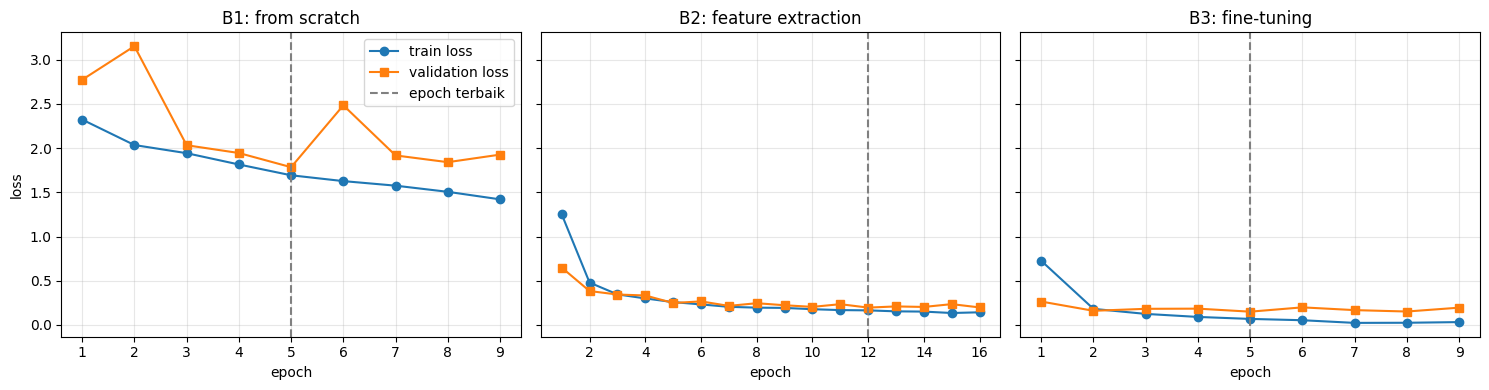

In [ ]:
def plot_curves(names, titles, filename):
    fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, name, title in zip(axes, names, titles):
        h = pd.DataFrame(results[name]["history"])
        ax.plot(h["epoch"], h["train_loss"], "o-", label="train loss")
        ax.plot(h["epoch"], h["val_loss"], "s-", label="validation loss")
        ax.axvline(results[name]["summary"]["best_epoch"], linestyle="--", color="gray", label="epoch terbaik")
        ax.set_title(title)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("loss")
    axes[0].legend()
    plt.tight_layout()
    plt.savefig("results/figures/" + filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_curves(["B1", "B2", "B3"], ["B1: from scratch", "B2: feature extraction", "B3: fine-tuning"],
            "learning_curves_B1_B2_B3.png")

Train loss dihitung saat training (dengan augmentasi), sedangkan validation loss dihitung tanpa augmentasi. Karena itu pada awal training train loss bisa lebih besar dari validation loss.

Tabel di bawah dipakai untuk melihat overfitting. Train accuracy dan train loss dihitung ulang memakai model terbaik tanpa augmentasi, supaya bisa dibandingkan dengan validation.

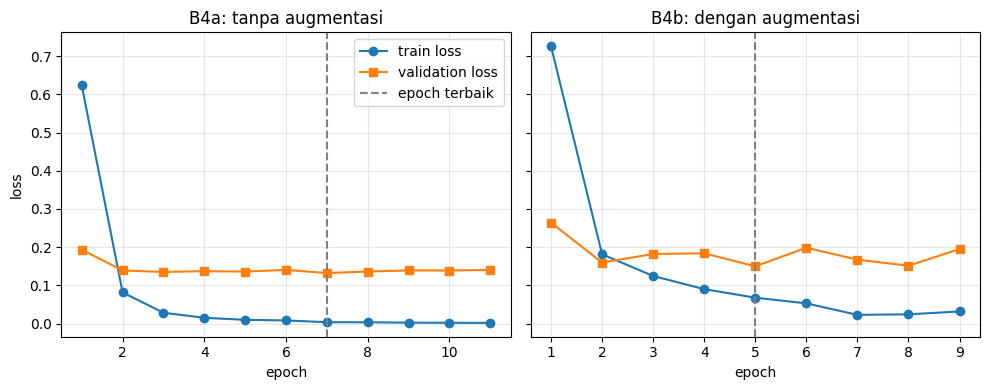

,Kode,Train Acc,Val Acc,Gap Acc,Train Loss,Val Loss,Gap Loss,Test Acc,Test Macro F1
0,B1,0.3822,0.3311,0.0511,1.6851,1.7849,0.0998,0.3533,0.2977
1,B2,0.9592,0.9398,0.0194,0.1334,0.1958,0.0624,0.9033,0.9029
2,B3,0.9914,0.9498,0.0416,0.0338,0.1499,0.1161,0.9367,0.9368
3,B4a,1.0000,0.9599,0.0401,0.0009,0.1323,0.1314,0.9333,0.9340
4,B4b,0.9914,0.9498,0.0416,0.0338,0.1499,0.1161,0.9367,0.9368
5,B5,0.9957,0.9732,0.0225,0.0139,0.0852,0.0713,0.9533,0.9537


In [ ]:
gap_rows = []
for kode, run in rows:
    s = results[run]["summary"]
    gap_rows.append({
        "Kode": kode,
        "Train Acc": round(s["train_acc"], 4),
        "Val Acc": round(s["val_acc"], 4),
        "Gap Acc": round(s["acc_gap"], 4),
        "Train Loss": round(s["train_loss"], 4),
        "Val Loss": round(s["val_loss"], 4),
        "Gap Loss": round(s["loss_gap"], 4),
        "Test Acc": round(s["test_acc"], 4),
        "Test Macro F1": round(s["test_f1"], 4),
    })

gap = pd.DataFrame(gap_rows)
gap.to_csv("results/overfitting_gap.csv", index=False)

plot_curves(["B4_noaug", "B3"], ["B4a: tanpa augmentasi", "B4b: dengan augmentasi"], "learning_curves_B4.png")
gap

## 12. Failure analysis

Model terbaik dipilih dari akurasi validation. Dari test set diambil sampai 8 gambar yang salah diprediksi dengan confidence paling tinggi.

model terbaik (validation): B5
jumlah salah: 14 dari 300


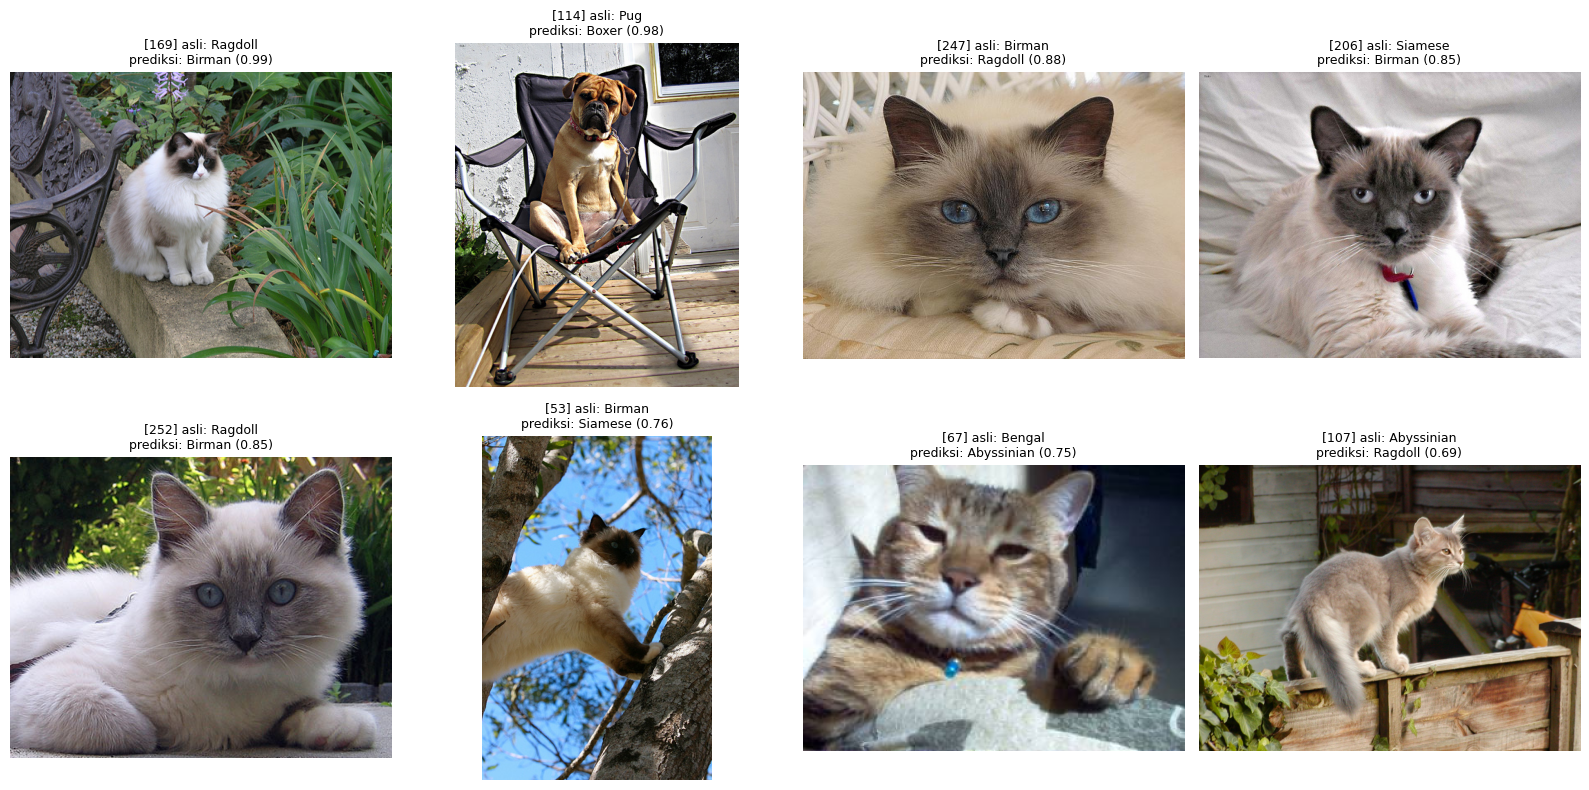

,test_index,ground_truth,prediction,confidence,second_choice,true_class_prob
0,169,Ragdoll,Birman,0.9943,Ragdoll,0.0051
1,114,Pug,Boxer,0.9796,Pug,0.0158
2,247,Birman,Ragdoll,0.8816,Birman,0.1183
3,206,Siamese,Birman,0.8525,Ragdoll,0.0642
4,252,Ragdoll,Birman,0.8503,Ragdoll,0.1313
5,53,Birman,Siamese,0.7570,Birman,0.2384
6,67,Bengal,Abyssinian,0.7498,Bengal,0.2493
7,107,Abyssinian,Ragdoll,0.6889,Abyssinian,0.2841


In [ ]:
candidates = ["B1", "B2", "B3", "B4_noaug", "B5"]
best_run = candidates[0]
for c in candidates:
    if results[c]["summary"]["val_acc"] > results[best_run]["summary"]["val_acc"]:
        best_run = c
print("model terbaik (validation):", best_run)

probs = results[best_run]["probs"]
preds = results[best_run]["preds"]
true = results[best_run]["labels"]
confidence = probs.max(axis=1)

errors = np.where(preds != true)[0]
order = errors[np.argsort(-confidence[errors])]
print("jumlah salah:", len(errors), "dari", len(true))

records = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for a in axes:
    a.axis("off")

for k in range(min(8, len(order))):
    i = order[k]
    img = Image.open(test_data.paths[i]).convert("RGB")
    axes[k].imshow(img)
    axes[k].set_title("[" + str(i) + "] asli: " + class_names[true[i]] + "\nprediksi: " + class_names[preds[i]]
                      + " (" + str(round(confidence[i], 2)) + ")", fontsize=9)
    top2 = np.argsort(-probs[i])[:2]
    records.append({
        "test_index": int(i),
        "ground_truth": class_names[true[i]],
        "prediction": class_names[preds[i]],
        "confidence": round(float(confidence[i]), 4),
        "second_choice": class_names[top2[1]],
        "true_class_prob": round(float(probs[i][true[i]]), 4),
    })

plt.tight_layout()
plt.savefig("results/figures/failure_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

failure_df = pd.DataFrame(records)
failure_df.to_csv("results/failure_cases.csv", index=False)
failure_df

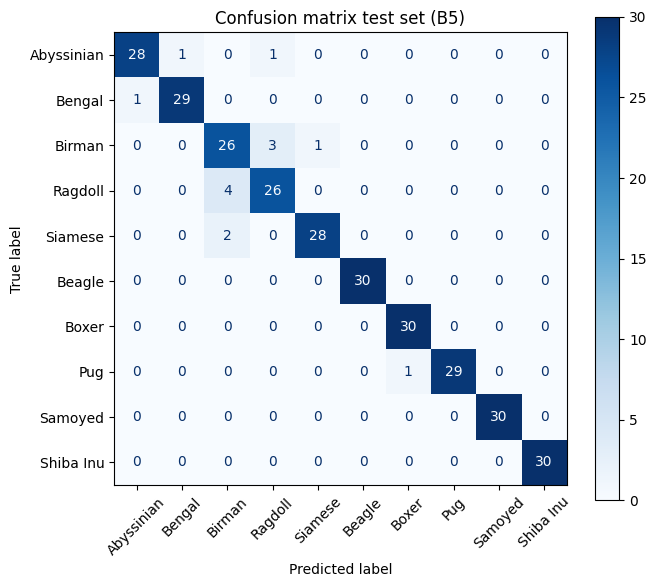

              precision    recall  f1-score   support

  Abyssinian      0.966     0.933     0.949        30
      Bengal      0.967     0.967     0.967        30
      Birman      0.812     0.867     0.839        30
     Ragdoll      0.867     0.867     0.867        30
     Siamese      0.966     0.933     0.949        30
      Beagle      1.000     1.000     1.000        30
       Boxer      0.968     1.000     0.984        30
         Pug      1.000     0.967     0.983        30
     Samoyed      1.000     1.000     1.000        30
   Shiba Inu      1.000     1.000     1.000        30

    accuracy                          0.953       300
   macro avg      0.954     0.953     0.954       300
weighted avg      0.954     0.953     0.954       300



In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(true, preds, display_labels=class_names, xticks_rotation=45,
                                        cmap="Blues", ax=ax)
ax.set_title("Confusion matrix test set (" + best_run + ")")
plt.tight_layout()
plt.savefig("results/figures/confusion_matrix_best.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(true, preds, target_names=class_names, digits=3))

## 13. Tambahan: Grad-CAM layer4 (B2 vs B3)

Grad-CAM menunjukkan bagian gambar yang paling berpengaruh untuk kelas yang benar. B2 dipakai sebagai kondisi sebelum fine-tuning dan B3 sebagai sesudah fine-tuning.

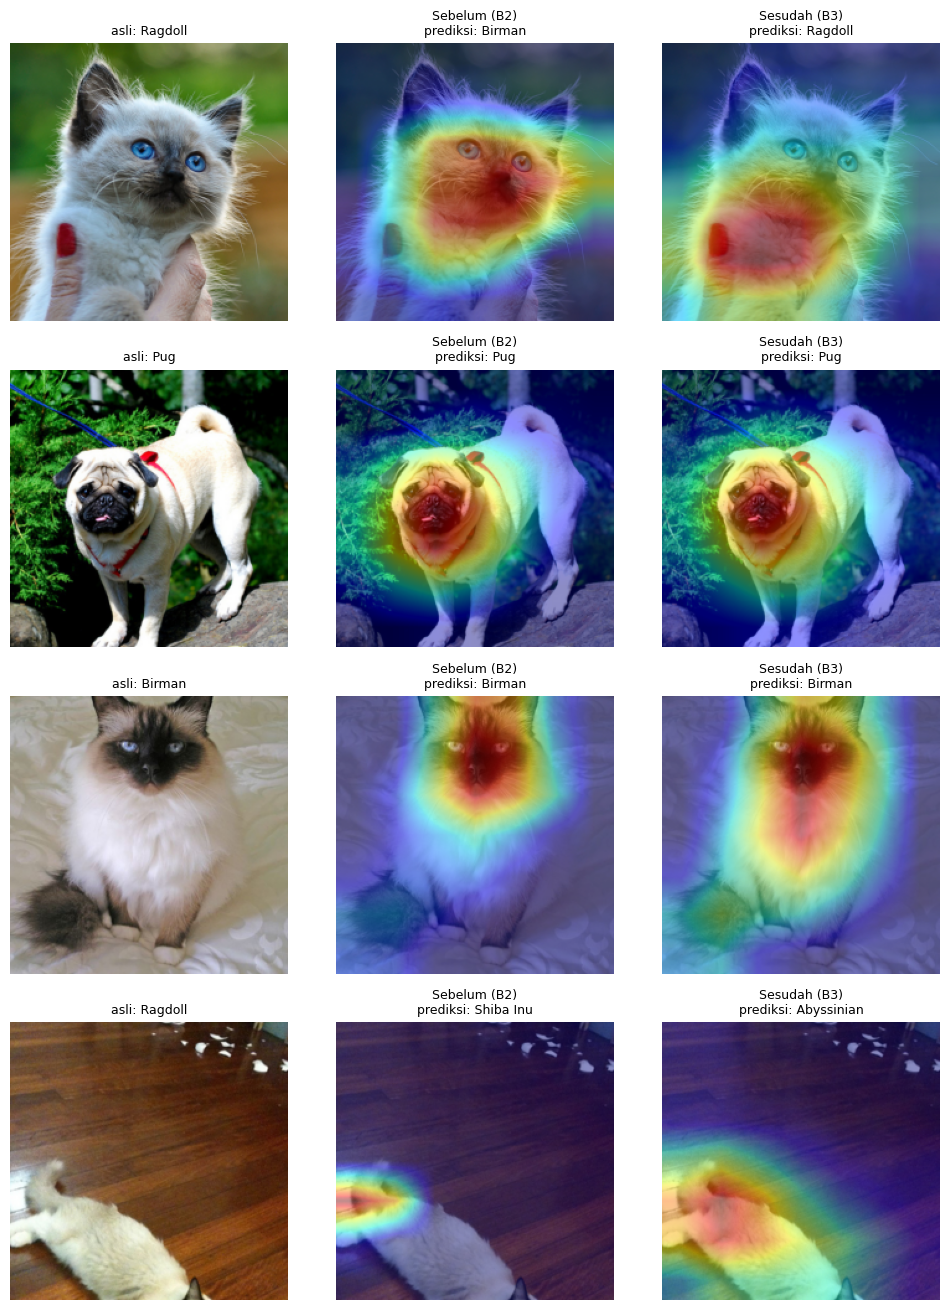

In [ ]:
def load_trained(name):
    model, groups = get_model("resnet18", results[name]["summary"]["mode"])
    model.load_state_dict(results[name]["state"])
    model.eval()
    return model


def grad_cam(model, x, target):
    feats = []

    def hook(module, inp, out):
        feats.append(out)

    handle = model.layer4.register_forward_hook(hook)
    x = x.unsqueeze(0).to(device)
    x.requires_grad_(True)
    out = model(x)
    handle.remove()

    grads = torch.autograd.grad(out[0, target], feats[0])[0]
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * feats[0]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    cam = cam / (cam.max() + 1e-8)
    pred = out[0].argmax().item()
    return cam, pred


model_before = load_trained("B2")
model_after = load_trained("B3")

b3_preds = results["B3"]["preds"]
b3_true = results["B3"]["labels"]
picked = list(np.where(b3_preds == b3_true)[0][:3]) + list(np.where(b3_preds != b3_true)[0][:1])

fig, axes = plt.subplots(len(picked), 3, figsize=(10, 3.3 * len(picked)))
for r, i in enumerate(picked):
    x, y = test_data[i]
    img = denorm(x)
    axes[r, 0].imshow(img)
    axes[r, 0].set_title("asli: " + class_names[y], fontsize=9)
    for c, (model, title) in enumerate([(model_before, "Sebelum (B2)"), (model_after, "Sesudah (B3)")]):
        cam, pred = grad_cam(model, x, y)
        axes[r, c + 1].imshow(img)
        axes[r, c + 1].imshow(cam, cmap="jet", alpha=0.45)
        axes[r, c + 1].set_title(title + "\nprediksi: " + class_names[pred], fontsize=9)
    for c in range(3):
        axes[r, c].axis("off")

plt.tight_layout()
plt.savefig("results/figures/gradcam_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Simpan hasil

Semua file hasil (log, tabel, gambar) ada di folder `results`. Cell di bawah membuat file zip dari folder itu.

In [ ]:
save_logs()
print(os.listdir("results"))

shutil.make_archive("hasil_tugas05", "zip", "results")
try:
    from google.colab import files
    files.download("hasil_tugas05.zip")
except Exception:
    print("zip tersimpan sebagai hasil_tugas05.zip")

['failure_cases.csv', 'tabel_konsolidasi.md', 'raw_summary.csv', 'overfitting_gap.csv', 'raw_metrics.json', 'raw_epoch_log.csv', 'figures']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>